# 📘 Notebook 8 — Case Study 3.1: Styrene Free-Radical Polymerization
| | |
|---|---|
| ⏱ Time | ~35 min (simulations ≈ 30 s) |
| 🧭 Type | **steady state Monte Carlo**: isothermal CSTR at steady state |
| 🎯 Goal | reproduce **Table 3.3** and **Figures 3.3–3.6** of the book with the book's parameters |
| 📖 Book | Sec. 3.1 · Tables 3.1–3.3 · Algorithms 3.1 and 3.2 |

This notebook is about the **code**: how each equation and each line of the algorithm becomes Python. Derivations: *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

**Mechanism (Table 3.1):** initiator decomposition `I → 2R` · initiation `R + M → P₁` · propagation `Pₙ + M → Pₙ₊₁` · transfer to monomer `Pₙ → Dₙ + P₁` · combination `Pₙ + Pₘ → Dₙ₊ₘ`.

## 0 · Setup, and why we need Numba
With `P_p ≈ 0.9997`, chains are ~5,000 units long, so 100,000 chains need about **a billion random numbers**. Plain Python would take many minutes.

**Numba** (already installed in Colab) fixes that. Put `@njit` on the line above a function, and Numba compiles it to fast machine code (book Sec. 5.2, *Compilation versus Interpretation*). The code inside stays ordinary Python. Two small differences:
- inside an `@njit` function we use `np.random.random()` instead of `random.random()`;
- the first call of each function takes a few seconds extra while it compiles.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

## 1 · Kinetic parameters (Table 3.2)
Every rate constant has the Arrhenius form `k = A·exp(−E/RT)`, with `E` in cal/mol and `R = 1.987` cal/(K·mol). Units: min⁻¹ and L/(mol·min).

In [2]:
R_gas = 1.987                  # cal/(K·mol)
T = 90 + 273.15                # K

def arrhenius(A, E):
    return A * np.exp(-E / (R_gas * T))

In [3]:
kd  = arrhenius(1.6945e15, 31500)    # 1/min
kp  = arrhenius(1.302e9,   7759)     # L/(mol·min)
ktM = arrhenius(5.14e9,   15230)     # L/(mol·min)
ktc = arrhenius(4.92e11,   3470)     # L/(mol·min)

In [4]:
f = 0.7          # initiator efficiency
I = 0.92e-3      # mol/L
M = 8.0          # mol/L

## 2 · From rate constants to probabilities
**Step 1, QSSA** (Eq. 3.9): the concentration of polymer radicals.

In [5]:
P_rad = np.sqrt(f * kd * I / ktc)
print(f"[P] = {P_rad:.4e} mol/L   (book: 5.468e-09)")

[P] = 5.4679e-09 mol/L   (book: 5.468e-09)


**Step 2, probability of propagation** (Eq. 3.10) and **of combination** (Eq. 3.12):

In [6]:
Rp_rel  = kp * M              # propagation (per radical)
RtM_rel = ktM * M             # transfer to monomer
Rtc_rel = 2 * ktc * P_rad     # combination

Pp  = Rp_rel / (Rp_rel + RtM_rel + Rtc_rel)
Ptc = Rtc_rel / (Rtc_rel + RtM_rel)
print(f"P_p = {Pp:.4f}   P_tc = {Ptc:.4f}   (book: 0.9997 and 0.6102)")

P_p = 0.9997   P_tc = 0.6102   (book: 0.9997 and 0.6102)


**Step 3, dimensionless groups** for the analytical solution (Eqs. 3.15–3.16):

In [7]:
beta = 2 * ktc * P_rad / (kp * M)
tau = ktM / kp
print(f"β = {beta:.6f}   τ = {tau:.6f}   (book: 0.000197 and 0.000126)")

β = 0.000197   τ = 0.000126   (book: 0.000197 and 0.000126)


## 3 · The algorithms in code
### 3.1 · Growing one polymer radical
Lines 2–11 of Algorithms 3.1 and 3.2: start at `n = 1` (instantaneous initiation), add one unit while `Rnd ≤ P_p`.

In [8]:
@njit
def grow_chain(Pp):
    n = 1
    while np.random.random() <= Pp:
        n += 1
    return n

### 3.2 · Algorithm 3.1 (contains the "unforgivable" flaw)
After the first chain stops, one more `Rnd` decides **how**: combination (`Rnd ≤ P_tc`) or transfer to monomer. `D` is the book's counting vector, `D[n]` = number of dead chains of length `n`; we make it long enough (`n_max`).

In [9]:
@njit
def algorithm_3_1(N, Pp, Ptc, n_max, seed):
    np.random.seed(seed)
    D = np.zeros(n_max, np.int64)
    for i in range(N):
        n = grow_chain(Pp)                 # lines 2–11
        if np.random.random() <= Ptc:      # line 13: combination
            m = grow_chain(Pp)             # second chain, never checked!
            D[n + m] += 1                  # line 24
        else:
            D[n] += 1                      # line 26: transfer
    return D

### 3.3 · Algorithm 3.2 (corrected)
The second radical must **also** decide how it ends. If it picks transfer (`Rnd > P_tc`), it's a dead chain on its own, and we build another partner, until one ends by combination (`repeat … until`, which in Python is `while True:` + `return`).

In [10]:
@njit
def generate_second_chain(Pp, Ptc, D):
    while True:                            # line 14: repeat
        m = grow_chain(Pp)
        if np.random.random() > Ptc:       # partner transfers
            D[m] += 1                      # line 27
        else:                              # until Rnd ≤ P_tc
            return m

In [11]:
@njit
def algorithm_3_2(N, Pp, Ptc, n_max, seed):
    np.random.seed(seed)
    D = np.zeros(n_max, np.int64)
    for i in range(N):
        n = grow_chain(Pp)
        if np.random.random() <= Ptc:
            m = generate_second_chain(Pp, Ptc, D)
            D[n + m] += 1                  # line 30
        else:
            D[n] += 1                      # line 32
    return D

### 3.4 · Averages from the counting vector
`Nn = Σ n·D / Σ D`  and  `Nw = Σ n²·D / Σ n·D`

In [12]:
def averages(D):
    n = np.arange(len(D))
    Nn = np.sum(n * D) / np.sum(D)
    Nw = np.sum(n**2 * D) / np.sum(n * D)
    return Nn, Nw

And the analytical (instantaneous distribution) values, Eqs. 3.17–3.18:

In [13]:
def analytical_averages(beta, tau):
    Nn = 1 / (tau + beta / 2)
    Nw = (2 * tau + 3 * beta) / (beta + tau)**2
    return Nn, Nw

## 4 · Reproducing Table 3.3
Three cases: only combination (`τ = 0`), only transfer (`β = 0`), and both. In terms of β and τ the probabilities are `P_p = 1/(1 + β + τ)` and `P_tc = β/(β + τ)`.

In [14]:
def probabilities(beta, tau):
    Pp = 1 / (1 + beta + tau)
    Ptc = beta / (beta + tau)
    return Pp, Ptc

In [15]:
N = 100_000
n_max = 500_000

Pp1, Ptc1 = probabilities(beta, 0.0)
D_comb = algorithm_3_2(N, Pp1, Ptc1, n_max, 1)          # only combination

In [16]:
Pp2, Ptc2 = probabilities(0.0, tau)
D_trans = algorithm_3_2(N, Pp2, Ptc2, n_max, 1)         # only transfer

In [17]:
D_both = algorithm_3_2(N, Pp, Ptc, n_max, 1)            # both

Put the results next to the book's Table 3.3:

In [18]:
table = pd.DataFrame(index=["Nn (MC)", "Nn (ID)", "Nw (MC)", "Nw (ID)"])
cases = [("τ = 0", D_comb, beta, 0.0), ("β = 0", D_trans, 0.0, tau), ("both", D_both, beta, tau)]

for name, D, b, t in cases:
    Nn, Nw = averages(D)
    Nn_id, Nw_id = analytical_averages(b, t)
    table[name] = [round(Nn), round(Nn_id), round(Nw), round(Nw_id)]
table

,τ = 0,β = 0,both
Nn (MC),10118,7941,4451
Nn (ID),10151,7947,4457
Nw (MC),15134,15842,8050
Nw (ID),15227,15894,8085


The book's values (Table 3.3):

| | τ = 0 | β = 0 | both |
|---|---|---|---|
| Nn (MC) | 10159 | 7948 | 4447 |
| Nn (ID) | 10151 | 7947 | 4457 |
| Nw (MC) | 15246 | 15908 | 8087 |
| Nw (ID) | 15227 | 15894 | 8085 |

Monte Carlo values are random, so they won't match to the last digit, but both should be within ~0.5 % of the analytical solution.

## 5 · Figure 3.3: the two limiting cases
The analytical w-CLD (Eq. 3.14) and the Monte Carlo w-CLD (chains grouped in bins of `Δn = 200`) are computed in the collapsed helper cell.

In [19]:
#@title Helpers: analytical and Monte Carlo w-CLD
def analytical_wcld(beta, tau, n):
    s = beta + tau
    return n*s*(tau + 0.5*beta*s*n)*np.exp(-s*n)                 # Eq. 3.14
def mc_wcld(D, dn=200):
    n = np.arange(len(D)); last = np.nonzero(D)[0].max()
    edges = np.arange(1, last + dn, dn)
    mass, _ = np.histogram(n, bins=edges, weights=n*D)
    return 0.5*(edges[1:] + edges[:-1]), mass / mass.sum() / dn
print("helpers ready")

helpers ready


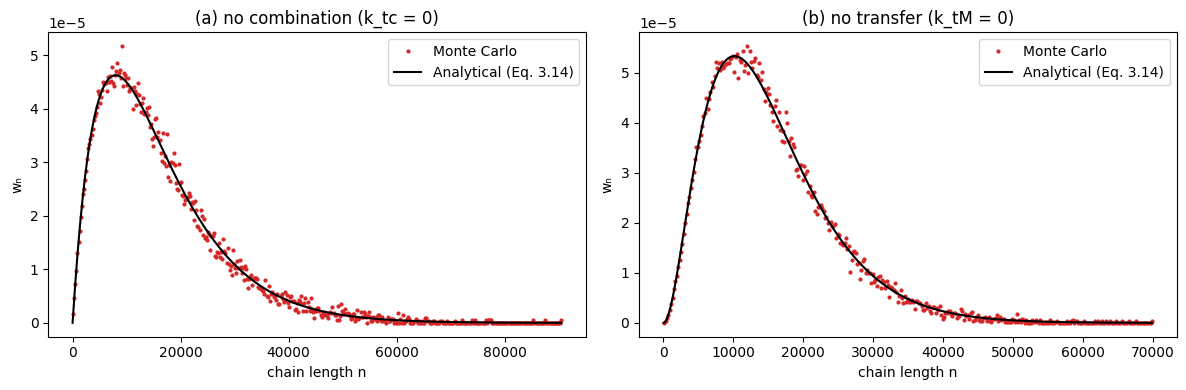

In [20]:
#@title Plot Figure 3.3
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, D, b, t, title in [(ax[0], D_trans, 0.0, tau, "(a) no combination (k_tc = 0)"), (ax[1], D_comb, beta, 0.0, "(b) no transfer (k_tM = 0)")]:
    x, w = mc_wcld(D); a.plot(x, w, ".", ms=4, c="tab:red", label="Monte Carlo")
    nn = np.linspace(1, x.max(), 600); a.plot(nn, analytical_wcld(b, t, nn), "k-", label="Analytical (Eq. 3.14)")
    a.set_xlabel("chain length n"); a.set_ylabel("wₙ"); a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

## 6 · Figures 3.4 and 3.6: catching the flaw
With **both** termination modes active, run the flawed Algorithm 3.1 too:

In [21]:
D_flawed = algorithm_3_1(N, Pp, Ptc, n_max, 1)

print(f"Algorithm 3.1: Nn = {averages(D_flawed)[0]:.0f}")
print(f"Algorithm 3.2: Nn = {averages(D_both)[0]:.0f}")
print(f"analytical:    Nn = {analytical_averages(beta, tau)[0]:.0f}")

Algorithm 3.1: Nn = 4977
Algorithm 3.2: Nn = 4451
analytical:    Nn = 4457


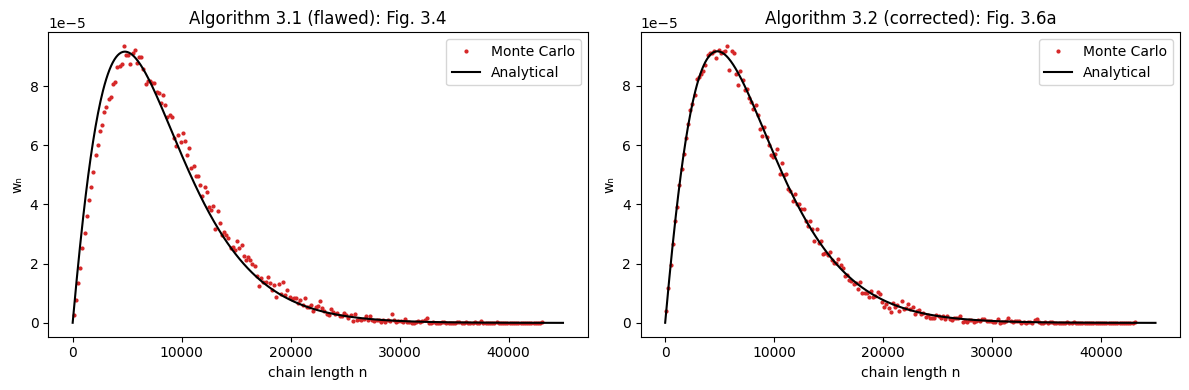

In [22]:
#@title Plot Figures 3.4 and 3.6a
nn = np.linspace(1, 45_000, 600); w_an = analytical_wcld(beta, tau, nn)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, D, title in [(ax[0], D_flawed, "Algorithm 3.1 (flawed): Fig. 3.4"), (ax[1], D_both, "Algorithm 3.2 (corrected): Fig. 3.6a")]:
    x, w = mc_wcld(D); a.plot(x, w, ".", ms=4, c="tab:red", label="Monte Carlo")
    a.plot(nn, w_an, "k-", label="Analytical"); a.set_xlabel("chain length n"); a.set_ylabel("wₙ"); a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

### Optional: Figure 3.6b with 1,000,000 chains
Ten times more chains gives a visibly smoother w-CLD (about a minute). Change `False` to `True` to run it.

In [23]:
RUN_1M = False
if RUN_1M:
    D_1M = algorithm_3_2(1_000_000, Pp, Ptc, n_max, 2)
    x, w = mc_wcld(D_1M)
    plt.plot(x, w, ".", ms=3, c="tab:red")
    plt.plot(nn, w_an, "k-")
    plt.show()

## ✅ What the code taught us
- Every probability is a ratio of rates; the QSSA gives the one unknown concentration, `[P]`.
- The algorithm is a **direct translation** of the decision tree, and its loops must mirror the mechanism exactly. One missing check (the partner radical's termination) shifts the whole distribution.
- Always validate against limiting cases or analytical solutions when they exist.

### 🧪 Try it yourself
1. Change the temperature to 70 °C and re-run from section 1. Which way does Nn move, and why?
2. Double `I`. Which probability changes, and by how much?
3. Replace `grow_chain` with `np.random.geometric(1 - Pp)` and compare the run time (book Sec. 5.3).

➡️ **Next: Notebook 9 — Case Study 3.2: styrene/MMA copolymerization**